The gating dynamics of a K$^+$ channel are described by:
\begin{align}
    \tau_n(V)\frac{dn}{dt} &= n_\infty(V) - n \\
    g_K(t) &= \bar{g}_K n(t)^4
\end{align}
where $n(t)$ is the probability of a single subunit being open, and $g_K(t)$ is the total channel conductance. We will use simplified sigmoidal functions for the voltage-dependent steady-state $(n_\infty)$ and time constant $(\tau_n)$:
\begin{align*}
    n_\infty(V) &= \frac{1}{1 + e^{-(V-V_0)/10}} \\
    \tau_n(V) &= 1 + 5e^{-(V-V_0)^2/50^2}
\end{align*}
Use the following physiological parameters: $\bar{g}_K = 1.0 \text{ (mS/cm}^2\text{)}$, $V_0=-25.0 \text{ (mV)}$,

In [2]:
import PyDSTool as dst
# The tool we will use for Dynamical Systems is PyDSTool https://github.com/robclewley/pydstool
import numpy as np
from matplotlib import pyplot as plt

In [8]:
# 0. Plt Style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 14, 'figure.figsize': (12, 8), 'axes.labelweight': 'bold', 'figure.titleweight': 'bold'})

# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="simple_K_channel")

# Define the parameters
pars = {
    "V0": -25.0,
    "g_K_bar": 1.0,
    "V_hold": -70.0,
    "V_test": 20.0,
    "t_step": 5.0
}

# Define aux functions
fnspecs = {
    "V": (['t'], "if(t < t_step, V_hold, V_test)"),
    "n_inf": (['v'], "1 / (1 + exp(-(v - V0) / 10))"),
    "tau_n": (['v'], "1 + 5 * exp(-(v - V0)^2 / 50^2)"),
    "g_K": (['n'], "g_K_bar * n^4")
}

# Define the ODEs.
varspecs = {
    "n": "(n_inf(V(t)) - n) / tau_n(V(t))",
}

# Define the initial conditions. 
ics = {
    "n": 1 / (1 + np.exp(-(-70.0 - -25.0) / 10)),
}

DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics

Computing trajectory...


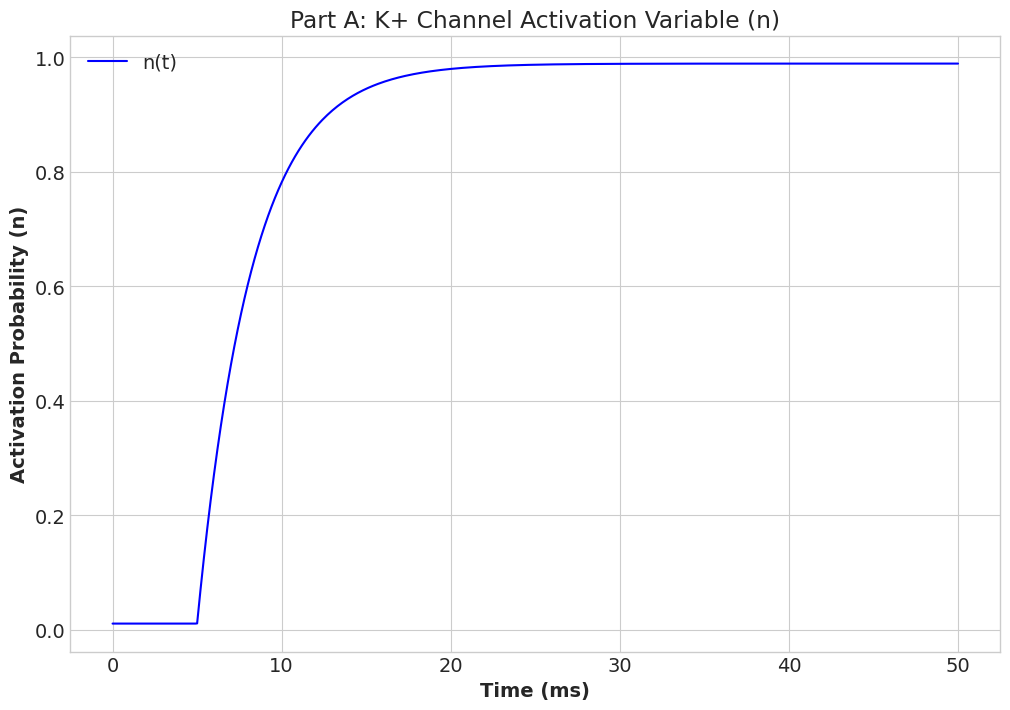

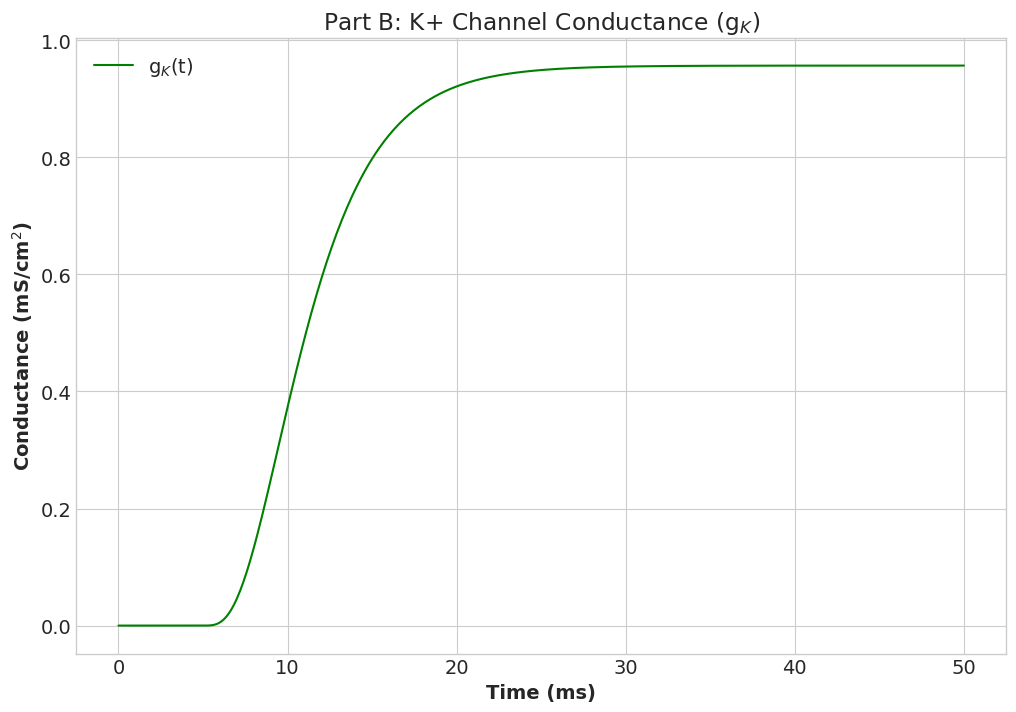

In [9]:
# 2. Compute the trajectory
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# define time
ode_sys.set(tdata=[0, 50])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample(dt=0.1)

# Plotting n(t)
plt.figure()
plt.plot(points['t'], points['n'], label='n(t)', color='blue')
plt.title('Part A: K+ Channel Activation Variable (n)')
plt.xlabel('Time (ms)')
plt.ylabel('Activation Probability (n)')
plt.legend()
plt.grid(True)
plt.show()

# plot gkt
g_K_t = pars['g_K_bar'] * (points['n']**4)

plt.figure()
plt.plot(points['t'], g_K_t, label='g$_K$(t)', color='green')
plt.title('Part B: K+ Channel Conductance (g$_K$)')
plt.xlabel('Time (ms)')
plt.ylabel('Conductance (mS/cm$^2$)')
plt.legend()
plt.grid(True)
plt.show()

Next, you will model the sodium channel to understand the critical role of voltage alignment. The sodium channel conductance is described by an activation ($m$) and an inactivation ($h$) gate:
$$ g_{Na}(t) = \bar{g}_{Na} m(t)^3 h(t)\,. $$
The gating variables are governed by their own independent ODEs:
\begin{align}
    \tau_m(V)\frac{dm}{dt} &= m_\infty(V) - m \\
    \tau_h(V)\frac{dh}{dt} &= h_\infty(V) - h\,,
\end{align}
 where we choose steady-state functions
\begin{align*}
    m_\infty(V) &= \frac{1}{1 + e^{-(V-V_0^m)/k_m}} \\
    h_\infty(V) &= \frac{1}{1 + e^{(V-V_0^h)/k_h}}
\end{align*}
and parameters $\bar{g}_{Na} = 1.0 \text{ (mS/cm}^2\text{)}$, $V_0^m=-30.0 \text{ (mV)}$, $V_0^h=-50.0 \text{ (mV)}$, $k_m=8$, and $k_h=5$. Define the time constants as: $\tau_m(V) = 0.5$ ms and $\tau_h(V) = 5.0$ ms. Note that $\tau_m \ll \tau_h$.

In [ ]:
# =============================================================================
# For this and the rest of the lab tasks: create code accordingly 
# =============================================================================

In [33]:
# 0. Plt Style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 14, 'figure.figsize': (12, 8), 'axes.labelweight': 'bold', 'figure.titleweight': 'bold'})

# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="simple_K_channel")

# Define the parameters
pars = {
    "V0_m": -30.0,
    "V0_h": -50.0,
    "k_m": 8.0,
    "k_h": 5.0,
    "tau_m": 0.5,
    "tau_h": 5.0,
    "g_Na_bar": 1.0,
    "V_hold": -70.0,
    "V_test": 20.0,
    "t_step": 5.0
}

# Define aux functions
fnspecs = {
    "V": (['t'], "if(t < t_step, V_hold, V_test)"),
    "m_inf": (['v'], "1 / (1 + exp(-(v - V0_m) / k_m))"),
    "h_inf": (['v'], "1 / (1 + exp(-(v - V0_h) / k_h))"),
    "g_Na": (['m', 'h'], "g_Na_bar * m^3 * h")
}

# Define the ODEs.
varspecs = {
    "m": "(m_inf(V(t)) - m) / tau_m",
    "h": "(h_inf(V(t)) - h) / tau_h",
}

# Define the initial conditions. 
ics = {
    "m": 1 / (1 + np.exp(-(-70.0 - (-30.0)) / 8.0)),
    "h": 1 / (1 + np.exp(-(-70.0 - (-50.0)) / 5.0)),
}

DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics

Computing trajectory...


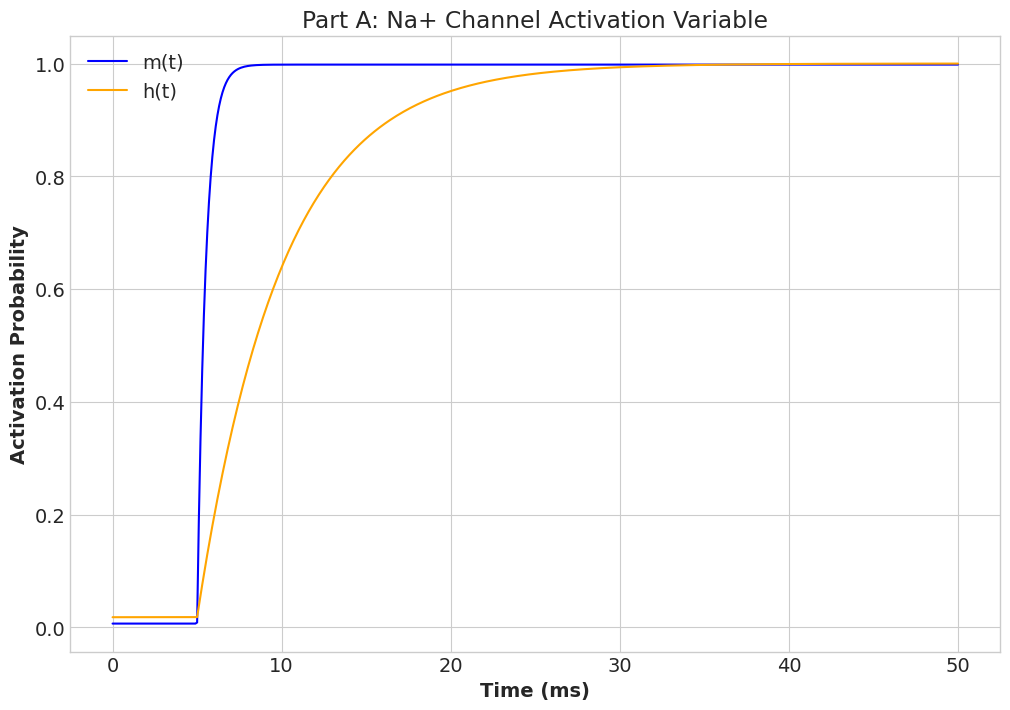

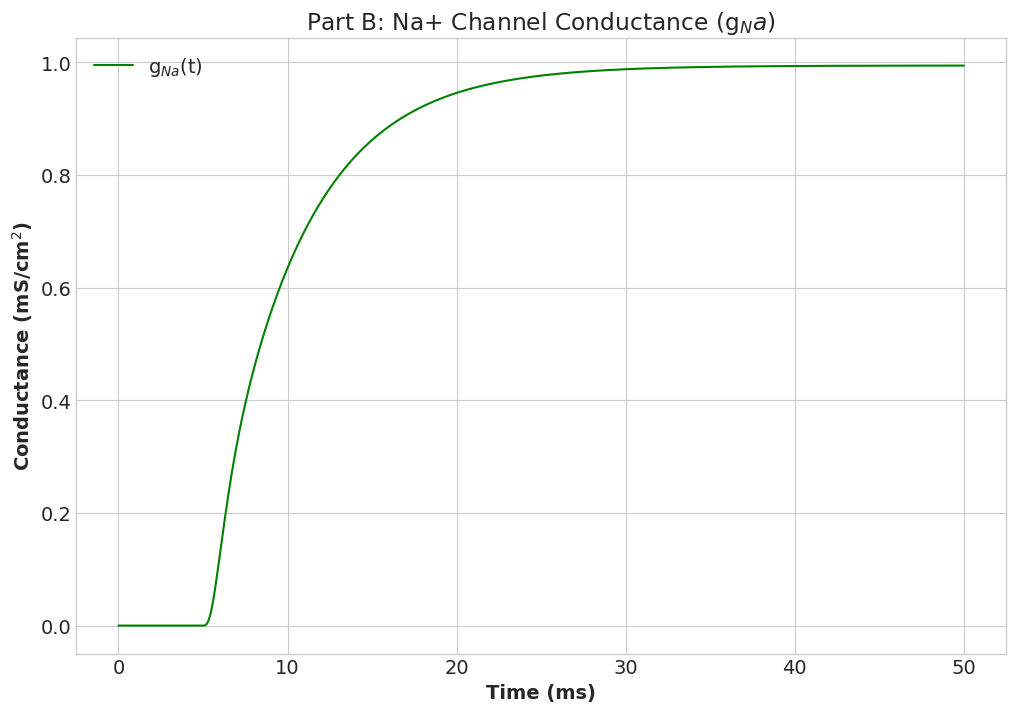

In [ ]:
# 2. Compute the trajectory
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# define time
ode_sys.set(tdata=[0, 50])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample(dt=0.1)

# Plotting m(t)
fig_1, ax_1 = plt.subplots(figsize=(12, 8))
ax_1.plot(points['t'], points['m'], label='m(t)', color='blue')
ax_1.plot(points['t'], points['h'], label='h(t)', color='orange')
ax_1.set_title('Part A: Na+ Channel Activation Variable' )
ax_1.set_xlabel('Time (ms)')
ax_1.set_ylabel('Activation Probability')
ax_1.legend()
ax_1.grid(True)
plt.show()

# plot gkt
g_Na_t = DSargs.pars['g_Na_bar'] * (points['m']**3) * points['h']

plt.figure()
plt.plot(points['t'], g_Na_t, label='g$_{Na}$(t)', color='green')
plt.title('Part B: Na+ Channel Conductance (g$_{Na}$)')
plt.xlabel('Time (ms)')
plt.ylabel('Conductance (mS/cm$^2$)')
plt.legend()
plt.grid(True)
plt.show()